In [ ]:
import re
import io
import contextlib
import logging
import numpy as np
import pandas as pd
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize, TreebankWordTokenizer
from nltk.probability import FreqDist

logging.getLogger("nltk").setLevel(logging.CRITICAL)
logging.getLogger("nltk.downloader").setLevel(logging.CRITICAL)
logging.disable(logging.CRITICAL)
for package in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    try:
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            nltk.download(package, quiet=True)
    except Exception:
        pass
logging.disable(logging.NOTSET)

def tokenize_words(text):
    try:
        return word_tokenize(text)
    except LookupError:
        return TreebankWordTokenizer().tokenize(text)

def tokenize_sentences(text):
    try:
        return sent_tokenize(text)
    except LookupError:
        return [sentence.strip() for sentence in re.split(r"(?<=[.!?])\s+", text.strip()) if sentence.strip()]

try:
    stop_words = set(stopwords.words("english"))
except LookupError:

    stop_words = set("a about after again all also am an and any are as at be because been before being below between both but by can could did do does doing down during each few for from further had has have having he her here hers herself him himself his how i if in into is it its itself just me more most my myself no nor not now of off on once only or other our ours ourselves out over own same she should so some such than that the their theirs them themselves then there these they this those through to too under until up very was we were what when where which while who whom why will with you your yours yourself yourselves".split())
    print("Note: NLTK stopwords data is unavailable; using a small fallback list. Download the NLTK 'stopwords' corpus for the full list.")

print("Setup complete.")

Setup complete.


In [ ]:
paragraph = (
    "Artificial intelligence is my favourite topic because it helps computers learn from data and solve useful problems. "
    "I enjoy studying machine-learning tools that recognize patterns and make predictions. "
    "These systems can help students, improve healthcare, and simplify daily tasks. "
    "I also like exploring how responsible AI protects privacy and reduces mistakes. "
    "In the future, I hope to build helpful applications that make learning easier for everyone."
)

clean_text = re.sub(r"[^a-zA-Z\s]", " ", paragraph.lower())
clean_text = re.sub(r"\s+", " ", clean_text).strip()
print("Lowercase text without punctuation:\n", clean_text)

sentences = tokenize_sentences(paragraph.lower())
print("\nSentence tokens:")
for sentence in sentences:
    print("-", sentence)

print("\nPython split():")
print(paragraph.split())
print("\nNLTK word_tokenize() (fallback only if NLTK tokenizer data is missing):")
print(tokenize_words(paragraph))
print("\nDifference: split() separates only at whitespace; word_tokenize() also separates punctuation into tokens.")

words = tokenize_words(clean_text)
filtered_words = [word for word in words if word not in stop_words]
print("\nWords after stopword removal:")
print(filtered_words)

frequency = FreqDist(filtered_words)
print("\nWord frequency (most common first):")
print(frequency.most_common())

Lowercase text without punctuation:
 artificial intelligence is my favourite topic because it helps computers learn from data and solve useful problems i enjoy studying machine learning tools that recognize patterns and make predictions these systems can help students improve healthcare and simplify daily tasks i also like exploring how responsible ai protects privacy and reduces mistakes in the future i hope to build helpful applications that make learning easier for everyone

Sentence tokens:
- artificial intelligence is my favourite topic because it helps computers learn from data and solve useful problems.
- i enjoy studying machine-learning tools that recognize patterns and make predictions.
- these systems can help students, improve healthcare, and simplify daily tasks.
- i also like exploring how responsible ai protects privacy and reduces mistakes.
- in the future, i hope to build helpful applications that make learning easier for everyone.

Python split():
['Artificial', 'inte

In [ ]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

alpha_words = re.findall(r"[A-Za-z]+", paragraph.lower())
filtered_alpha = [word for word in alpha_words if word not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stemmed_words = [stemmer.stem(word) for word in filtered_alpha]
try:
    lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_alpha]
except LookupError:
    lemmatized_words = None
    print("WordNet data is unavailable, so WordNet lemmatization was skipped. Run nltk.download('wordnet') and rerun this cell to get the real lemmas.")

print("Alphabetic words:", alpha_words)
print("\nAfter stopword removal:", filtered_alpha)
print("\nPorter stems:", stemmed_words)
if lemmatized_words is not None:
    print("\nWordNet lemmas:", lemmatized_words)
print("\nComparison: stemming chops word endings and may create non-words (e.g., 'studying' may become 'studi'). "
      "Lemmatization aims to return a dictionary word (e.g., plural nouns to singular forms). "
      "Use stemming for quick search/indexing; prefer lemmatization when readable, linguistically meaningful words matter.")

Alphabetic words: ['artificial', 'intelligence', 'is', 'my', 'favourite', 'topic', 'because', 'it', 'helps', 'computers', 'learn', 'from', 'data', 'and', 'solve', 'useful', 'problems', 'i', 'enjoy', 'studying', 'machine', 'learning', 'tools', 'that', 'recognize', 'patterns', 'and', 'make', 'predictions', 'these', 'systems', 'can', 'help', 'students', 'improve', 'healthcare', 'and', 'simplify', 'daily', 'tasks', 'i', 'also', 'like', 'exploring', 'how', 'responsible', 'ai', 'protects', 'privacy', 'and', 'reduces', 'mistakes', 'in', 'the', 'future', 'i', 'hope', 'to', 'build', 'helpful', 'applications', 'that', 'make', 'learning', 'easier', 'for', 'everyone']

After stopword removal: ['artificial', 'intelligence', 'favourite', 'topic', 'helps', 'computers', 'learn', 'data', 'solve', 'useful', 'problems', 'enjoy', 'studying', 'machine', 'learning', 'tools', 'recognize', 'patterns', 'make', 'predictions', 'systems', 'help', 'students', 'improve', 'healthcare', 'simplify', 'daily', 'tasks', 

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "The AI chatbot answers student questions quickly and helps learners study online.",
    "Solar energy uses sunlight to produce clean electricity and reduce pollution.",
    "The college library provides books, quiet study spaces, and internet access for students."
]
labels = ["AI chatbot", "Solar energy", "College library"]

count_vectorizer = CountVectorizer()
bow = count_vectorizer.fit_transform(texts)
print("BoW vocabulary:")
print(count_vectorizer.get_feature_names_out())
print("\nBoW document-term matrix (rows follow the text order):")
print(pd.DataFrame(bow.toarray(), index=labels, columns=count_vectorizer.get_feature_names_out()))

tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())
print("\nTF-IDF matrix (rounded):")
print(pd.DataFrame(np.round(tfidf_matrix.toarray(), 3), index=labels, columns=feature_names))

print("\nTop 3 TF-IDF keywords for each text:")
for label, row in zip(labels, tfidf_matrix.toarray()):
    top_indices = row.argsort()[::-1][:3]
    print(f"{label}: " + ", ".join(f"{feature_names[i]} ({row[i]:.3f})" for i in top_indices))

print("\nInterpretation: BoW stores word counts. TF-IDF gives higher relative importance to words that distinguish a document from the other documents.")

BoW vocabulary:
['access' 'ai' 'and' 'answers' 'books' 'chatbot' 'clean' 'college'
 'electricity' 'energy' 'for' 'helps' 'internet' 'learners' 'library'
 'online' 'pollution' 'produce' 'provides' 'questions' 'quickly' 'quiet'
 'reduce' 'solar' 'spaces' 'student' 'students' 'study' 'sunlight' 'the'
 'to' 'uses']

BoW document-term matrix (rows follow the text order):
                 access  ai  and  answers  books  chatbot  clean  college  \
AI chatbot            0   1    1        1      0        1      0        0   
Solar energy          0   0    1        0      0        0      1        0   
College library       1   0    1        0      1        0      0        1   

                 electricity  energy  ...  reduce  solar  spaces  student  \
AI chatbot                 0       0  ...       0      0       0        1   
Solar energy               1       1  ...       1      1       0        0   
College library            0       0  ...       0      0       1        0   

             

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

ai_text = '''Artificial intelligence learns patterns from data.\nAI systems analyze data to make predictions and automate tasks.\nThese digital systems support healthcare, education, and customer service.\nResponsible AI should protect privacy and improve security.'''
blockchain_text = '''Blockchain stores data in linked digital blocks.\nBlockchain systems verify transactions and records across a network.\nThese digital records can improve security and traceability.\nBlockchain supports payments, supply chains, and identity management.'''

def preprocess_tokens(text):
    tokens = re.findall(r"[a-zA-Z]+", text.lower())
    return [token for token in tokens if token not in stop_words]

ai_tokens = preprocess_tokens(ai_text)
blockchain_tokens = preprocess_tokens(blockchain_text)
set_ai, set_blockchain = set(ai_tokens), set(blockchain_tokens)
union = set_ai | set_blockchain
jaccard = len(set_ai & set_blockchain) / len(union) if union else 0.0

similarity_vectorizer = TfidfVectorizer(stop_words="english")
tech_vectors = similarity_vectorizer.fit_transform([ai_text, blockchain_text])
cosine = cosine_similarity(tech_vectors[0:1], tech_vectors[1:2])[0, 0]

print("AI tokens:", ai_tokens)
print("Blockchain tokens:", blockchain_tokens)
print(f"Jaccard similarity: {jaccard:.3f}")
print(f"Cosine similarity (TF-IDF): {cosine:.3f}")
print("\nAnalysis: Jaccard is easy to interpret as shared-word overlap. Cosine with TF-IDF is more informative for these descriptions because it compares weighted word vectors. However, neither method understands synonyms or meaning directly, so two related texts can still receive a low score when they use different vocabulary.")

AI tokens: ['artificial', 'intelligence', 'learns', 'patterns', 'data', 'ai', 'systems', 'analyze', 'data', 'make', 'predictions', 'automate', 'tasks', 'digital', 'systems', 'support', 'healthcare', 'education', 'customer', 'service', 'responsible', 'ai', 'protect', 'privacy', 'improve', 'security']
Blockchain tokens: ['blockchain', 'stores', 'data', 'linked', 'digital', 'blocks', 'blockchain', 'systems', 'verify', 'transactions', 'records', 'across', 'network', 'digital', 'records', 'improve', 'security', 'traceability', 'blockchain', 'supports', 'payments', 'supply', 'chains', 'identity', 'management']
Jaccard similarity: 0.128
Cosine similarity (TF-IDF): 0.143

Analysis: Jaccard is easy to interpret as shared-word overlap. Cosine with TF-IDF is more informative for these descriptions because it compares weighted word vectors. However, neither method understands synonyms or meaning directly, so two related texts can still receive a low score when they use different vocabulary.


Review 1: The headphones have excellent sound, clear calls, a comfortable fit, and long battery life. I love the quality and recommend them.
  Polarity=0.393, Subjectivity=0.569, Class=Positive

Review 2: The headphones sound terrible, the battery dies quickly, and the buttons are frustrating. I am very disappointed.
  Polarity=-0.328, Subjectivity=0.755, Class=Negative

Review 3: The package contains one headset, a USB cable, two replacement ear pads, and an instruction booklet. The box lists the model number and the warranty period.
  Polarity=0.000, Subjectivity=0.000, Class=Neutral



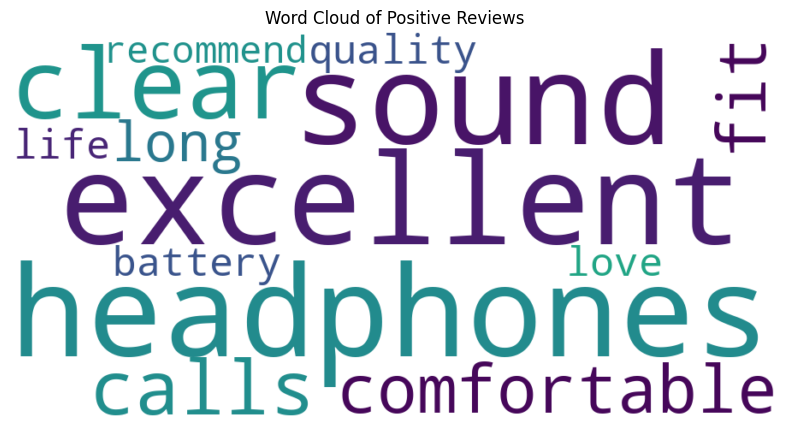

In [ ]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

reviews = [
    "The headphones have excellent sound, clear calls, a comfortable fit, and long battery life. I love the quality and recommend them.",
    "The headphones sound terrible, the battery dies quickly, and the buttons are frustrating. I am very disappointed.",
    "The package contains one headset, a USB cable, two replacement ear pads, and an instruction booklet. The box lists the model number and the warranty period."
]

positive_reviews = []
for number, review in enumerate(reviews, start=1):
    sentiment = TextBlob(review).sentiment
    polarity, subjectivity = sentiment.polarity, sentiment.subjectivity
    if polarity > 0.1:
        label = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        label = "Negative"
    else:
        label = "Neutral"
    print(f"Review {number}: {review}")
    print(f"  Polarity={polarity:.3f}, Subjectivity={subjectivity:.3f}, Class={label}\n")

if positive_reviews:
    positive_text = " ".join(positive_reviews)
    wordcloud = WordCloud(width=900, height=450, background_color="white").generate(positive_text)
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews were found, so a word cloud was not generated.")

In [ ]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_text = (
    "Technology can help students learn when it is used thoughtfully. Online lessons allow learners to review difficult topics at their own pace. "
    "Small coding projects turn ideas into practical skills, while teamwork teaches people to explain their decisions. "
    "A helpful study tool should give clear feedback, protect personal information, and encourage students to check facts instead of copying answers. "
    "Teachers can combine classroom discussion with digital resources to support different learning styles. "
    "Although technology saves time, regular practice and curiosity remain important. "
    "By setting goals, asking questions, and learning from mistakes, students can become more confident and use technology responsibly in everyday life."
)

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
token_list = tokenizer.texts_to_sequences([training_text])[0]
print("Vocabulary:", tokenizer.word_index)
print("Number of tokens:", len(token_list))

sequences = []
for i in range(1, len(token_list)):
    sequences.append(token_list[:i + 1])

max_seq_len = max(len(sequence) for sequence in sequences)
padded_sequences = pad_sequences(sequences, maxlen=max_seq_len, padding="pre")
X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

vocab_size = len(tokenizer.word_index) + 1
y_encoded = to_categorical(y, num_classes=vocab_size)
print("X shape:", X.shape, "| y shape:", y_encoded.shape)

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=10),
    LSTM(32),
    Dense(vocab_size, activation="softmax")
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

model.fit(X, y_encoded, epochs=50, verbose=1)

Vocabulary: {'to': 1, 'and': 2, 'technology': 3, 'can': 4, 'students': 5, 'their': 6, 'learning': 7, 'help': 8, 'learn': 9, 'when': 10, 'it': 11, 'is': 12, 'used': 13, 'thoughtfully': 14, 'online': 15, 'lessons': 16, 'allow': 17, 'learners': 18, 'review': 19, 'difficult': 20, 'topics': 21, 'at': 22, 'own': 23, 'pace': 24, 'small': 25, 'coding': 26, 'projects': 27, 'turn': 28, 'ideas': 29, 'into': 30, 'practical': 31, 'skills': 32, 'while': 33, 'teamwork': 34, 'teaches': 35, 'people': 36, 'explain': 37, 'decisions': 38, 'a': 39, 'helpful': 40, 'study': 41, 'tool': 42, 'should': 43, 'give': 44, 'clear': 45, 'feedback': 46, 'protect': 47, 'personal': 48, 'information': 49, 'encourage': 50, 'check': 51, 'facts': 52, 'instead': 53, 'of': 54, 'copying': 55, 'answers': 56, 'teachers': 57, 'combine': 58, 'classroom': 59, 'discussion': 60, 'with': 61, 'digital': 62, 'resources': 63, 'support': 64, 'different': 65, 'styles': 66, 'although': 67, 'saves': 68, 'time': 69, 'regular': 70, 'practice':

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.0000e+00 - loss: 4.5008
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.0196 - loss: 4.4984
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.0392 - loss: 4.4967
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.0490 - loss: 4.4952
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.0392 - loss: 4.4934
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.0392 - loss: 4.4908
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.0392 - loss: 4.4876
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.0392 - loss: 4.4806
Epoch 9/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.0392 - loss: 4.4701
Epoch 10/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.0392 - loss: 4.4538
Epoch 11/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.0392 - loss: 4.4443
Epoch 12/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.0392 - loss: 4.43

In [ ]:
def generate_text(seed_word, next_words=8):
    result = seed_word.lower()
    for _ in range(next_words):
        sequence = tokenizer.texts_to_sequences([result])[0]
        sequence = pad_sequences([sequence], maxlen=X.shape[1], padding="pre", truncating="pre")
        probabilities = model.predict(sequence, verbose=0)[0]
        probabilities[0] = 0.0
        next_id = int(np.argmax(probabilities))
        next_word = tokenizer.index_word.get(next_id, "")
        if not next_word:
            break
        result += " " + next_word
    return result

print("Generated text (3 sample lines):")
for seed in ["learning", "technology", "students"]:
    print("-", generate_text(seed, next_words=8))

Generated text (3 sample lines):
- learning used used used used used used used used
- technology used used used used used used used used
- students used used used used used used used used
